# Flujo
---

* La manera cómo se incorpora el control de flujo en el LP determina el orden de ejecución de un programa
* Los mecanismos del LP utilizados para especificar el orden de ejecución, pueden ordenarse en categorías:

| Categoría        |                                                                              | Ejemplos                                    |
| --               | --                                                                           | --                                          |
| **secuencia**    | orden de las sentencias para su ejecución                                    | asignaciones, if, ...                       |
| **selección**    | alternativa entre dos o más sentencias controlada por una condición booleana | if-then-else, switch-case                   |
| **iteración**    | causa que una o más sentencias se ejecuten cero o más veces | PERFORM-TIMES, for, foreach, while, do-while                 |
| **unidad**       | abstracción procedural                                                       | f() { ... }                                 |
| **recursión**    | funciones con posibilidad de llamarse a sí mismas                            | f() { caso-base; f(); }                     |
| **concurrencia** |                                                                              |                                             |
| **excepciones**  | eventos inusuales (ejemplo: división por cero, apertura de archivo inexistente) que deberían controlarse/manejarse para que el SW sea confiable y tolerante a fallas                                                                    | try-catch-finally, try-except-else-finally  |
| **eventos**      | el control de ejecución se basa en acciones producidas por el usuario o por el entorno | on event when condition do action |

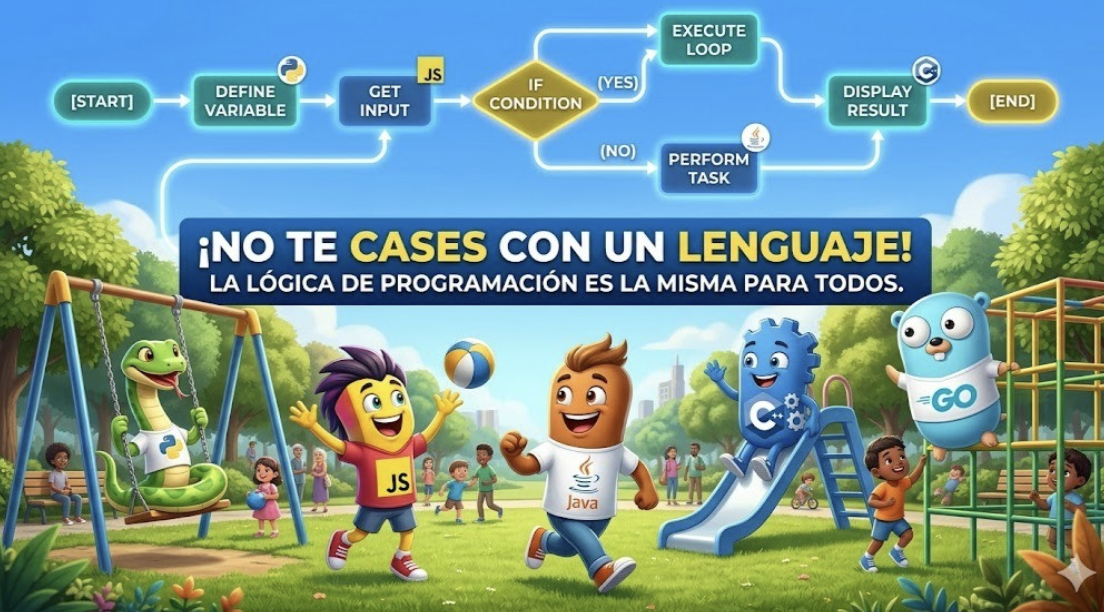

## Expresión

* Consiste de un objeto simple (constante o variable) o un operador o una función aplicada a una colección de operandos o argumentos (cada uno de los cuales define una expresión)
* Consta de:
  * Operadores (unarios, binarios o ternarios)
  * Operandos
  * Paréntesis
  * Llamadas a función

## Asignación

* En el **paradigma declarativo**, el cómputo consiste en **evaluar expresiones**
* En el **paradigma operacional**, el cómputo consiste en una **serie ordenada de cambios** (de los valores de las variables en memoria)

## Evaluación de Expresiones

| Tipo de Evaluación || Ejemplo |
| -- | -- | -- |
| **estricta o ansiosa**     | los argumentos de una función o los operandos de la expresión son siempre completamente evaluados antes de la aplicación de la función u operador. Tradicionalmente usada por los LP | sumar(2+1); al parámetro le llega 3 |
| **no estricta o perezosa** | los argumentos de una función o los operandos de la expresión no son evaluados a menos que sean utilizados en el cuerpo de la función o sean necesarios para determinar el valor de la expresión | sumar(2+1); al parámetro le llega 2+1 |


## Tipos de Control de Flujo

| Tipos | | |
| -- | -- | -- |
| **no estructurado** | se provee a través de saltos condicionales e incondicionales | if E1 C1: **goto** L1 |
| **estructurado**    | correspondencia entre el orden del texto del programa y el orden de la ejecución, permitiendo legibilidad, verificación, mantenimiento | ejecución **top-down**, con opciones de sentencias **break** y **continue** |

## Subprogramas

* Los LP operativos brindan mecanismos para dividir el programa en unidades, cada una de las cuales tiene cierta coherencia y lógica
* Su incorporación fomenta:

|                  |                                                                   |
| --               | --                                                                |
| **eficiencia**   | permiten factorizar el código                                     |
| **legibilidad**  | metodología de diseño top-down                                    |
| **verificación** | una unidad puede pensarse como un mapeo entre dominios de valores |

* Los LP permiten que un programa esté compuesto por subprogramas (secuencia de sentencias de un programa)
* En general se las llama rutinas, procedimientos, métodos, funciones (un valor), llaves o delimitadores, closures o funciones lambda

### Ejemplo

In [10]:
def f1():
    return 3 + 2

### Atributos

|                                  | |
| --                               | -- |
| **nombre**                       | identificador que se introduce en su declaración para invocar a la rutina |
| **alcance**                      | segmento de código dentro del cual el subprograma puede invocarse (si incluye al mismo subprograma acepta recursividad). Rango de instrucciones donde se conoce su nombre |
| **ambiente de referenciamiento** | puede ser: **local** (entidades declaradas dentro de la rutina) o **no local** (referencias a entidades declaradas en otros subprogramas cuyo alcance es visible en la rutina). Toda variable no locales que pueda ser referenciada por cualquier subprograma en el programa se llaman variables globales |
| **lista de parámetros**          | permiten la comunicación del subprograma con el resto del programa. Si se admiten parámetros de diferentes tipos el subprograma es polimórfico |
| **encabezado/declaración**       | formado por el nombre del subprograma, la lista de parámetros y el tipo del resultado |
| **cuerpo**                       | formado por las declaraciones locales y la sección ejecutable |
| **definición**                   | declaración + cuerpo |

In [11]:
def suma(n):               # ENCABEZADO = DECLARACIÓN
    s = 0                  # cuerpo 
    for i in range(1, n):  # cuerpo
        s += i             # cuerpo
    return s               # cuerpo

### Parámetros

* Hay dos maneras de hacerle llegar los datos sobre los cuales computar a una unidad, a través del:
  * acceso a variables no locales visibles para la unidad
  * pasaje de parámetros
* Los datos pasados como parámetros son accedidos a través de nombres que son locales a la unidad
* El pasaje de parámetros es más flexible, ya que define computación parametrizada
* El uso de variables no locales puede conducir a programas menos confiable

| Tipo de parámetro | | Ejemplo |
| -- | -- | -- |
| **formal**                 | se declaran/definen en el encabezado de la unidad; aclarando en general su tipo | def sumar(a, b): |
| **actual/real/argumentos** | son variables, constantes, expresiones que se utilizan en la invocación de la unidad | sumar(2, 3) |

### Binding entre parámetros formales y reales

| Asociación sintáctica | | Ejemplos |
| -- | -- | -- |
| **posicional**             | asociación por la posición de los parámetros en la definición (formales) y la invocación (reales). Se ligan uno a uno | PROCEDURE P(x:INTEGER; y:FLOAT; z:INTEGER); <br> BEGIN <br> END; <br> P(a, b, c); |
| **faltantes o implícitos** | sólo pueden estar al final de los parámetros de la función. No es posible que un parámetro del medio pueda faltar | def ff(str1, a=1, str2='No'): <br> pass <br> ff('Hola') <br> ff('Hola', 2) <br> ff('Hola', 2, 'que tal') |
| **explícito**              | el llamador debe conocer los nombres de los parámetros formales. Útil cuando existen muchos parámetros faltantes y se quieren pasar pocos | def ff(str1, a=1, str2='No'): <br> pass <br> ff('Hola', a=3) <br> ff('Hola', str2='¿cómo andas?') |
| **anónimo**                | cantidad variable de parámetros. El invocado no conoce la cantidad ni el tipo de los parámetros | void ff(int a, ...); <br> ... <br> ff(x, y, 3); |

| Asociación semántica | | Ejemplo |
| -- | -- | -- |
| **referencia**    | se crea un "alias" entre cada parámetro real y su correspondiente parámetro formal. Referencian la misma celda de memoria. Las modificaciones sobre el parámetro formal se reflejan en el parámetro real | void ff(int& i) { i = 3; } <br> int a = 4; <br> ff(a); |
| **copia o valor** | se copian los valores  de los parámetros reales en los parámetros formales. Los parámetros reales y formales se desacoplan | void ff(int i) { i = 3; } <br> int a = 4; <br> ff(a); |

### Genérico

* Los subprogramas factorean un segmento de código, que se ejecutará en diferentes puntos mediante una invocación customizada a través de los parámetros
* Si difieren en algún detalle que no pueden resolver los parámetros debe repetirse la codificación
  * Una rutina para ordenar arreglos de enteros
  * Otra rutina para ordenar arreglos de strings
* Se puede parametrizar el tipo (C++, Ada, Java)
* Una rutina genérica es un molde
* Cada instanciación genera una rutina específica ligando el parámetro genérico al parámetro real durante la compilación

### Pasaje de funciones como parámetros

In [12]:
def x(a):
  print(a)

def y(z, t):
  z(t)

y(x, 1)

1


### Sobrecarga

* Un nombre con mas de una entidades
* Hay suficiente información para permitir establecer la ligadura unívocamente

```
class A {
    void m() {}
    void m(int i) {}
    void m(boolean b) {}
}
```

### Closures

* Aportan características funcionales al LP
* Permite igualar las funciones con las variables
* Proporcionan mayor flexibilidad a las funciones
* Permiten que un objeto retorne un método sin necesidad de dar acceso a sus propios atributos
* Permite implementar funciones generadoras de funciones
* LP que tienen closures: ML, Lisp, Perl, Ruby, Python, JavaScript, PHP, C++, Java, Rust, GO, entre otros
* Función evaluada o ejecutada en un ámbito diferente al cual fue definida
* Puede hacer uso de variables no presentes en su ámbito de evaluación
* El LP debe proveer un mecanismo para que la función acceda a las variables del ámbito correspondiente

In [13]:
def a():
    x = 2
    def b():        # es un closure
      y = 3
      print(x + y)
    return b

z = a
z()

<function __main__.a.<locals>.b()>